# K-Nearest Neighbors, start to finish
## Will this customer repay the loan, or default?

**What we are building:** a model that looks at a loan customer's details and predicts one of two answers:

- `0` = the customer repays the loan
- `1` = the customer **defaults** (stops repaying)

**The method:** K-Nearest Neighbors (KNN).

**KNN in one sentence:** to predict the answer for a new customer, find the K past customers whose details are most similar to the new one, and go with the answer most of them had.

**The flow of this notebook** (each step feeds the next one):

| Step | What we do | Why |
|---|---|---|
| 1 | Import the libraries | Tools for tables, charts and KNN |
| 2 | Create 1,000 customers | We need data with known answers |
| 3 | Look at the table | Know the columns before using them |
| 4 | Draw charts of the data | See which columns separate defaulters from repayers |
| 5 | Do KNN by hand for one customer | Understand exactly what the library will do |
| 6 | Split into train and test | Keep some customers hidden to check the model honestly |
| 7 | Scale the columns | Stop the big-number columns from controlling the distance |
| 8 | Train the first model | See a first result |
| 9 | Find the best K | K changes the answer, so we test many values |
| 10 | Final check on the hidden customers | The real score of the model |
| 11 | See how K changes the prediction areas | A picture of small K vs large K |
| 12 | Predict for brand new customers | Use the model |
| 13 | Summary and practice tasks | Revise |

You do not need any prior machine learning knowledge. Run the cells from top to bottom.

---
# Step 1: Import the libraries

A library is code that someone else has already written, which we can use. We need five of them.

In [1]:
# numpy: fast maths on lists of numbers. We use it to create random numbers and to calculate distances.
import numpy as np

# pandas: lets us work with data as a table (rows and columns), like an Excel sheet inside Python.
import pandas as pd

# matplotlib: the basic chart-drawing library.
import matplotlib.pyplot as plt

# seaborn: sits on top of matplotlib and draws statistical charts with less code.
import seaborn as sns

# train_test_split: cuts our table into a "training" part and a "testing" part.
# cross_val_score: tests a model several times on different slices of the training data.
from sklearn.model_selection import train_test_split, cross_val_score

# StandardScaler: brings every column to the same range, so no column dominates the distance.
from sklearn.preprocessing import StandardScaler

# KNeighborsClassifier: the KNN model itself.
from sklearn.neighbors import KNeighborsClassifier

# make_pipeline: joins "scale the data" and "run KNN" into one object, so we never forget to scale.
from sklearn.pipeline import make_pipeline

# These three measure how good the predictions are.
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Two fixed colours used in every chart, so the meaning never changes:
# blue = customer repaid, orange = customer defaulted.
BLUE = "#2a78d6"
ORANGE = "#eb6834"

# A clean white chart background with light grid lines.
sns.set_theme(style="whitegrid")

# Show rupee amounts as normal numbers (500000) instead of scientific notation (5e+05).
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Confirm the cell ran.
print("Libraries are ready.")

Libraries are ready.


---
# Step 2: Create the dataset (1,000 loan customers)

We do not have a real bank's data, so we generate it. Each row is one customer. Each customer has 6 details and 1 answer.

| Column | Meaning | Typical values |
|---|---|---|
| `age` | Age in years | 21 to 60 |
| `monthly_income` | Salary per month in rupees | 15,000 to 1,50,000 |
| `credit_score` | A score from 300 to 900 given by credit bureaus (like CIBIL). Higher = better repayment history | around 680 |
| `loan_amount` | Size of the loan in rupees | 2 to 14 times the monthly income |
| `missed_payments` | How many EMIs the customer missed in the last 12 months | 0 to 5 |
| `years_employed` | Years of work experience | 0 to 39 |
| **`default`** | **The answer.** 1 = defaulted, 0 = repaid | 0 or 1 |

**How the answer is decided in our generated data:** we calculate a risk number for each customer. The risk goes **up** when the credit score is low, when there are more missed payments, and when the loan is large compared to income. The risk goes **down** with more years of employment. Then we add randomness, because in real life two customers with identical details do not always behave the same.

Note that `age` and `monthly_income` (on its own) do **not** affect the risk. We kept them in on purpose. We will see later what such columns do to KNN.

In [2]:
# A random number generator with a fixed starting point (42).
# Fixing it means everyone who runs this notebook gets the same 1,000 customers.
rng = np.random.default_rng(42)

# How many customers we want.
n_customers = 1000

# Age: a whole number from 21 to 60 for each customer (61 is not included).
age = rng.integers(21, 61, n_customers)

# Monthly income: centred around 60,000 with a spread of 22,000.
# clip() keeps every value between 15,000 and 1,50,000. round(-2) rounds to the nearest 100.
monthly_income = rng.normal(60000, 22000, n_customers).clip(15000, 150000).round(-2)

# Credit score: centred around 680 with a spread of 80, kept within the real range of 300 to 900.
credit_score = rng.normal(680, 80, n_customers).clip(300, 900).round()

# Loan amount: between 2 and 14 times the monthly income, rounded to the nearest 1,000.
loan_amount = (monthly_income * rng.uniform(2, 14, n_customers)).round(-3)

# Missed payments: most customers miss 0, 1 or 2. A few miss more.
missed_payments = rng.poisson(1.2, n_customers).clip(0, 8)

# Years employed: cannot be more than (age - 20), so a 25-year-old gets at most 5 years.
years_employed = (rng.uniform(0, 1, n_customers) * (age - 20)).round()

# How big is the loan compared to income? A loan of 6,00,000 on a 60,000 salary gives 10.
loan_to_income = loan_amount / monthly_income

# The risk number. Each line pushes the risk up (+) or down (-).
risk = (
    -0.022 * (credit_score - 680)       # lower credit score  -> higher risk
    + 0.85 * (missed_payments - 1.2)    # more missed EMIs    -> higher risk
    + 0.30 * (loan_to_income - 8)       # bigger loan vs pay  -> higher risk
    - 0.06 * (years_employed - 8)       # longer employment   -> lower risk
    - 1.5                               # keeps defaulters in the minority, as in real life
)

# Convert the risk number into a chance between 0 and 1 (0.80 means an 80% chance of default).
default_chance = 1 / (1 + np.exp(-risk))

# The randomness: draw a random number for each customer.
# If it is smaller than their chance, they default (1). Otherwise they repay (0).
default = (rng.uniform(0, 1, n_customers) < default_chance).astype(int)

# Put all the columns together into one table.
df = pd.DataFrame({
    "age": age,
    "monthly_income": monthly_income.astype(int),
    "credit_score": credit_score.astype(int),
    "loan_amount": loan_amount.astype(int),
    "missed_payments": missed_payments,
    "years_employed": years_employed.astype(int),
    "default": default,
})

# Save the table as a CSV file so it can be opened in Excel or reused later.
df.to_csv("loan_customers.csv", index=False)

# shape gives (number of rows, number of columns).
print("Table created. Rows and columns:", df.shape)

Table created. Rows and columns: (1000, 7)


**Reading the output:** `(1000, 7)` means 1,000 rows (customers) and 7 columns (6 details + 1 answer). The same table is also saved as `loan_customers.csv` next to this notebook.

---
# Step 3: Look at the table

Before any modelling, we check three things: what the rows look like, what range each column has, and how many customers defaulted.

In [3]:
# head() shows the first 5 rows of the table.
df.head()

,age,monthly_income,credit_score,loan_amount,missed_payments,years_employed,default
0,24,91500,725,826000,1,4,0
1,51,62000,689,705000,1,14,0
2,47,72800,706,475000,1,16,0
3,38,58800,742,126000,2,6,0
4,38,56300,615,457000,1,5,0


**Reading the output:** each row is one customer. Read the first row across: age, income, credit score, loan amount, missed EMIs, years employed, and finally `default`. A `1` in the last column means that customer defaulted.

Two words used from here on:

- **Features** = the 6 detail columns. These are the inputs.
- **Target** = the `default` column. This is what we want to predict.

In [4]:
# describe() gives summary numbers for every column.
# .T flips the result so each column of our data becomes one row, which is easier to read.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"1,000.00",40.61,11.55,21.00,30.00,41.00,51.00,60.00
monthly_income,"1,000.00","59,778.30","21,855.64","15,000.00","44,900.00","60,100.00","74,000.00","129,900.00"
credit_score,"1,000.00",673.00,80.69,435.00,619.75,677.00,727.00,900.00
loan_amount,"1,000.00","478,902.00","293,264.59","30,000.00","237,750.00","423,000.00","665,250.00","1,637,000.00"
missed_payments,"1,000.00",1.11,1.02,0.00,0.00,1.00,2.00,5.00
years_employed,"1,000.00",10.24,8.93,0.00,3.00,8.00,16.00,39.00
default,"1,000.00",0.29,0.46,0.00,0.00,0.00,1.00,1.00


**Reading the output:** look at the `min` and `max` columns.

- `loan_amount` goes from 30,000 to over 16,00,000.
- `monthly_income` goes from 15,000 to about 1,30,000.
- `credit_score` goes from 435 to 900.
- `missed_payments` goes only from 0 to 5.

**The columns are in completely different ranges.** A difference of 2 missed payments is a big deal for a bank. A difference of 2 rupees in loan amount is nothing. But to a distance formula, both are just "2". Remember this. It becomes the main issue in Step 7.

Also check the `count` column: every column says 1,000, so there are no missing values to fix.

Repaid    (0): 705
Defaulted (1): 295
Default rate : 29.5%


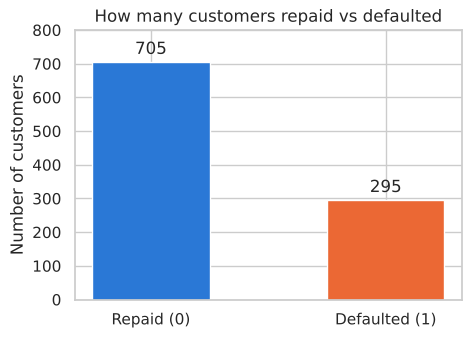

In [5]:
# value_counts() counts how many times each value appears in the default column.
counts = df["default"].value_counts().sort_index()

# Print the counts with clear labels.
print("Repaid    (0):", counts[0])
print("Defaulted (1):", counts[1])

# mean() of a 0/1 column gives the share of 1s. Multiply by 100 to get a percentage.
print(f"Default rate : {df['default'].mean() * 100:.1f}%")

# Create an empty chart area, 5 inches wide and 3.5 inches tall.
fig, ax = plt.subplots(figsize=(5, 3.5))

# Draw two bars: one for repaid, one for defaulted.
bars = ax.bar(["Repaid (0)", "Defaulted (1)"], counts.values, color=[BLUE, ORANGE], width=0.5)

# Write the exact count on top of each bar.
ax.bar_label(bars, padding=3)

# Label the vertical axis and give the chart a title.
ax.set_ylabel("Number of customers")
ax.set_title("How many customers repaid vs defaulted")

# Add space above the bars so the labels are not cut off.
ax.set_ylim(0, 800)

# Display the chart.
plt.show()

**Reading the output:** 705 customers repaid and 295 defaulted. So about 3 in 10 customers defaulted.

**Why this matters (the "do-nothing" score):** imagine a lazy model that says "repaid" for every single customer without looking at anything. It would be right for 705 out of 1,000 customers, which is **70.5% accuracy**. So 70.5% is the score of doing nothing. Our KNN model is only useful if it scores clearly **above 70.5%**. Always calculate this number before you get excited about a model's accuracy.

---
# Step 4: Explore the data with charts

**The question for this whole step:** which columns have different values for defaulters and for repayers?

This matters for KNN specifically. KNN decides using "similar customers". If defaulters and repayers have clearly different credit scores, then customers with similar credit scores tend to have the same answer, and KNN works. If a column looks the same for both groups, it tells KNN nothing.

## Chart 1: Histograms, one per feature

**How to read a histogram:** the horizontal axis is the value of the column. It is cut into ranges (bars). The height of a bar is how many customers fall in that range. We draw two histograms on top of each other: blue for repaid, orange for defaulted.

- If the blue and orange shapes sit in **different places**, the column separates the two groups. Useful.
- If the blue and orange shapes sit **on top of each other**, the column does not separate them. Not useful.

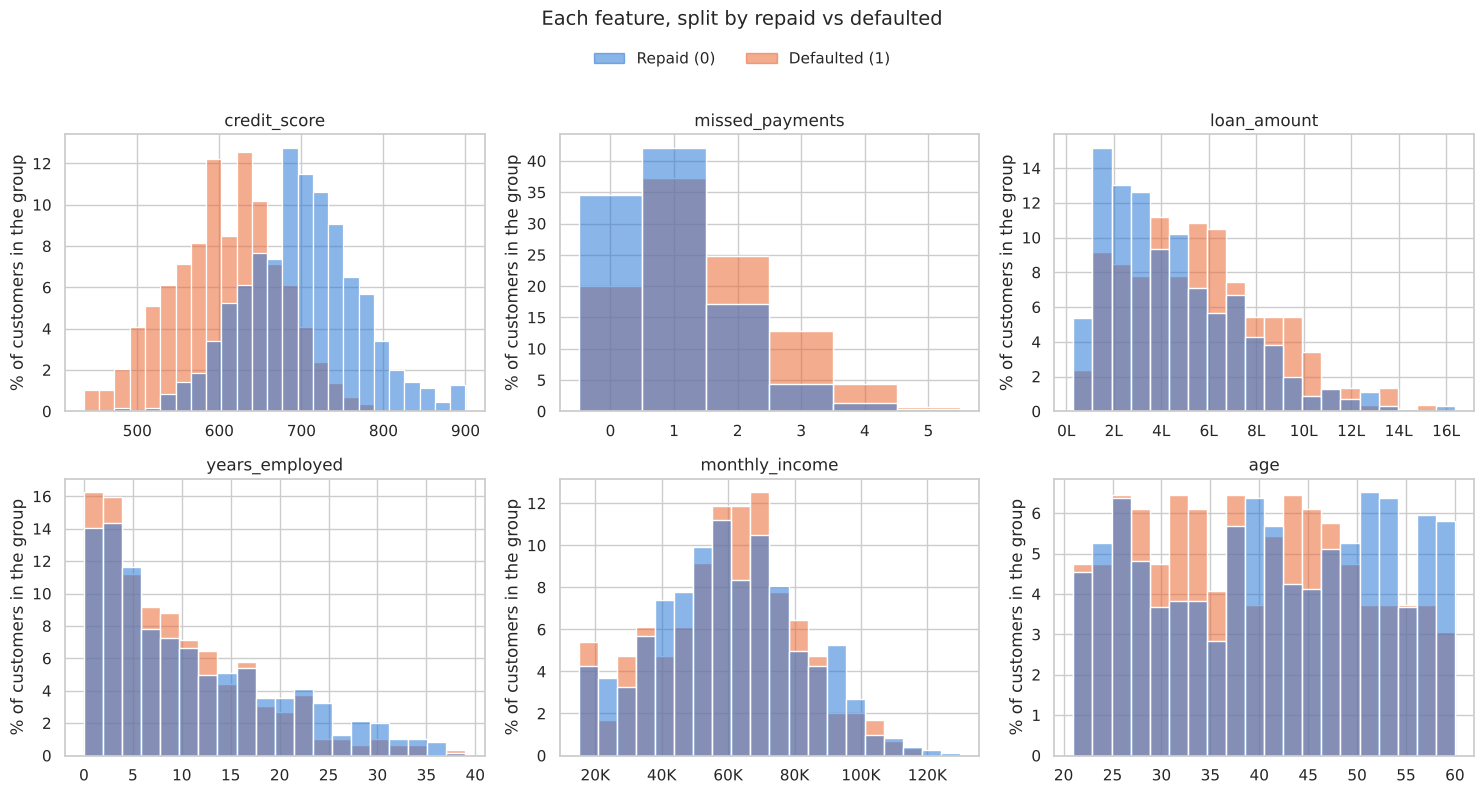

In [6]:
# The six feature columns, in the order we want to draw them.
feature_columns = ["credit_score", "missed_payments", "loan_amount",
                   "years_employed", "monthly_income", "age"]

# Create a grid of 2 rows and 3 columns of small charts (6 charts in total).
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# axes is a 2x3 grid. flatten() turns it into a simple list of 6 so we can loop over it.
# zip() pairs each chart area with one column name.
for ax, column in zip(axes.flatten(), feature_columns):

    # missed_payments is a small whole number (0 to 5), so each number gets its own bar.
    is_count_column = column == "missed_payments"

    # For the other columns, cut the range into 20 bars (25 for credit score, which has a wide range).
    number_of_bars = 25 if column == "credit_score" else 20

    # Draw the histogram for this column, split into two colours by the default column.
    sns.histplot(
        data=df,                                # the table to read from
        x=column,                               # which column goes on the horizontal axis
        hue="default",                          # split and colour by repaid (0) / defaulted (1)
        palette={0: BLUE, 1: ORANGE},           # which colour each group gets
        bins=6 if is_count_column else number_of_bars,   # how many bars to cut the range into
        discrete=is_count_column,               # centre each bar on the whole number
        stat="percent",                         # bar height = % of that group, not raw count
        common_norm=False,                      # each group adds up to 100% on its own
        alpha=0.55,                             # slightly see-through so overlap is visible
        legend=False,                           # we add one shared legend below instead
        ax=ax,                                  # draw on this small chart
    )

    # Title and axis labels for this small chart.
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("% of customers in the group")

    # Show rupee columns in thousands (60000 -> 60K) or lakhs (500000 -> 5L) so the axis is readable.
    if column == "monthly_income":
        ax.xaxis.set_major_formatter(lambda value, position: f"{value / 1000:.0f}K")
    if column == "loan_amount":
        ax.xaxis.set_major_formatter(lambda value, position: f"{value / 100000:.0f}L")

# One legend for the whole figure, built by hand so the colours are explained once.
legend_boxes = [plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.55),
                plt.Rectangle((0, 0), 1, 1, color=ORANGE, alpha=0.55)]
fig.legend(legend_boxes, ["Repaid (0)", "Defaulted (1)"], loc="upper center",
           bbox_to_anchor=(0.5, 0.955), ncol=2, frameon=False)

# A main title above everything, then tidy the spacing (leaving room at the top) and show.
fig.suptitle("Each feature, split by repaid vs defaulted", y=0.99, fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Reading the output, chart by chart:**

- **`credit_score`** — the orange shape sits clearly to the **left** of the blue one. Defaulters mostly have scores around 600, repayers around 700. This is the strongest separator in the data.
- **`missed_payments`** — at 0 and 1 missed payments the blue bar is taller. At 2, 3 and 4 the orange bars are taller. More missed EMIs go with more defaults.
- **`loan_amount`** — blue is taller on the left (loans below about 3 lakh) and orange is taller in the middle and right (6 to 10 lakh). Defaulters tend to have bigger loans, but the two shapes overlap a lot. A weak separator.
- **`years_employed`** — the two shapes are nearly the same. Blue is slightly taller beyond 20 years. A very weak separator.
- **`age`** — orange is a little taller at younger ages and blue a little taller above 50, but the bars jump up and down without a clear shape. A very weak separator.
- **`monthly_income`** — blue and orange sit on top of each other. On its own, this column does not separate the groups.

(The darker purple-grey colour is simply where the blue and orange bars overlap.)

**Why we used "% of the group" for bar height:** there are 705 repayers and only 295 defaulters. With raw counts, the blue bars would be taller everywhere just because there are more blue customers. Using percentages lets us compare the **shapes** fairly.

## Chart 2: Default rate for each number of missed payments

The histogram showed a pattern for `missed_payments`. This chart shows it as one clear number: out of the customers who missed exactly N payments, what percentage defaulted?

                 default_rate  customers
missed_payments                         
0                       19.50        303
1                       27.00        407
2                       37.60        194
3                       55.10         69
4                       59.10         22
5                       40.00          5


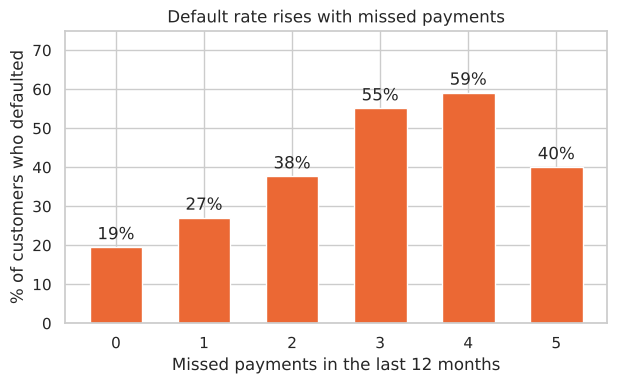

In [7]:
# Group customers by number of missed payments.
# For each group: mean of the 0/1 default column = share who defaulted, and count = group size.
by_missed = df.groupby("missed_payments")["default"].agg(default_rate="mean", customers="count")

# Convert the share (0.19) to a percentage (19.0).
by_missed["default_rate"] = by_missed["default_rate"] * 100

# Show the small table.
print(by_missed.round(1))

# Create the chart area.
fig, ax = plt.subplots(figsize=(7, 3.8))

# One bar per number of missed payments; the height is the default rate.
bars = ax.bar(by_missed.index, by_missed["default_rate"], color=ORANGE, width=0.6)

# Write the percentage above each bar.
ax.bar_label(bars, fmt="%.0f%%", padding=3)

# Labels, title and extra space above the bars.
ax.set_xlabel("Missed payments in the last 12 months")
ax.set_ylabel("% of customers who defaulted")
ax.set_title("Default rate rises with missed payments")
ax.set_ylim(0, 75)
plt.show()

**Reading the output:** among customers with 0 missed payments, 19.5% defaulted (the bar label rounds it to 19%). With 2 missed payments it is 38%. With 3 or 4 it is 55% to 59%. The more EMIs a customer missed, the more likely they defaulted.

**Look at the `customers` column in the printed table.** The bar for 5 missed payments drops to 40%, which looks odd. But only **5 customers** are in that group, so 40% means 2 people. A percentage calculated from 5 people is not reliable. Always check how many rows are behind a bar before trusting it.

## Chart 3: Correlation heatmap

**What correlation is:** a number between -1 and +1 that tells how two columns move together.

- Close to **+1**: when one goes up, the other goes up.
- Close to **-1**: when one goes up, the other goes down.
- Close to **0**: no straight-line link between them.

**How to read the heatmap:** every cell is the correlation between the row's column and the column's column. The most important part is the **bottom row (`default`)**, which shows how strongly each feature is linked to defaulting.

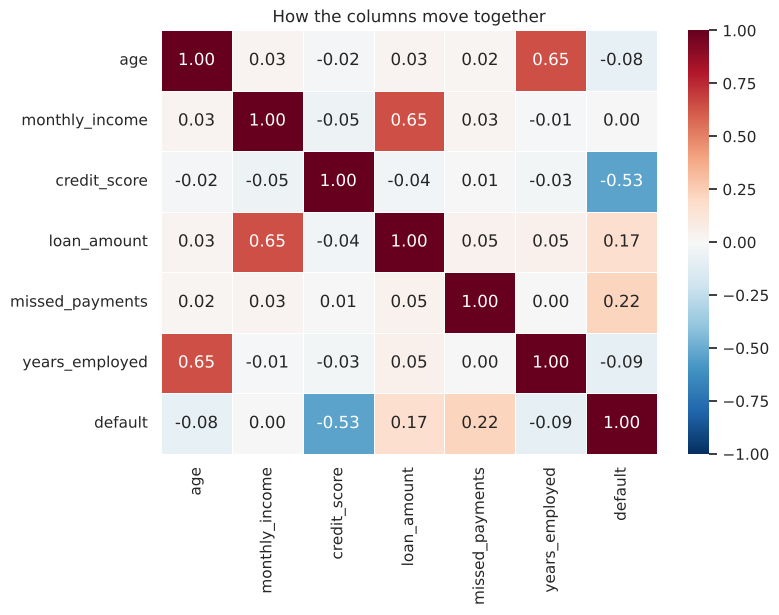

In [8]:
# corr() calculates the correlation between every pair of columns.
correlations = df.corr()

# Create the chart area.
fig, ax = plt.subplots(figsize=(8, 5.5))

# Draw the grid of coloured cells.
sns.heatmap(
    correlations,       # the table of correlation numbers
    annot=True,         # write the number inside each cell
    fmt=".2f",          # show 2 decimal places
    cmap="RdBu_r",      # red for positive, blue for negative, white near zero
    vmin=-1, vmax=1,    # fix the colour scale from -1 to +1
    center=0,           # 0 is the white middle point
    linewidths=0.5,     # thin white lines between the cells
    ax=ax,
)

# Title and show.
ax.set_title("How the columns move together")
plt.show()

**Reading the output (bottom row, `default`):**

- `credit_score` = **-0.53**. The strongest link, and it is negative: higher credit score, fewer defaults.
- `missed_payments` = **+0.22** and `loan_amount` = **+0.17**. Positive: more of these, more defaults.
- `age` = **-0.08** and `years_employed` = **-0.09**. Very weak.
- `monthly_income` = **0.00**. No link at all.

This matches what the histograms showed.

**Two other cells worth noticing:**

- `monthly_income` and `loan_amount` = **+0.65**. Makes sense: we generated loans as a multiple of income.
- `age` and `years_employed` = **+0.65**. Older customers have worked longer.

**One limit of correlation:** it looks at one column at a time. In our data, default risk depends on the loan **compared to** income, which needs two columns together. Correlation cannot show that, but KNN can use it, because KNN compares all columns of a customer at once.

## Chart 4: Scatter plot of the two strongest continuous features

**How to read a scatter plot:** every dot is one customer. The dot's left-right position is the credit score. The dot's up-down position is the loan amount. The colour is the answer.

This chart is the closest picture of how KNN "sees" the data: customers are points, and similar customers are points that sit close together.

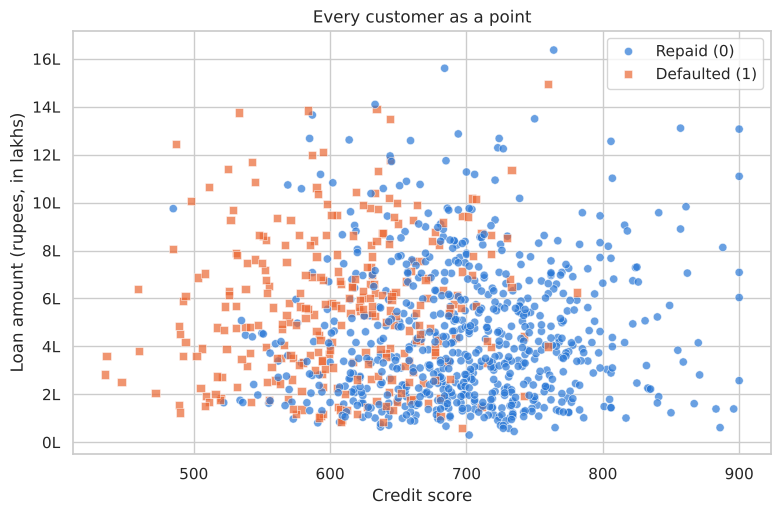

In [9]:
# Create the chart area.
fig, ax = plt.subplots(figsize=(9, 5.5))

# Draw one dot per customer.
sns.scatterplot(
    data=df,
    x="credit_score",                 # left-right position
    y="loan_amount",                  # up-down position
    hue="default",                    # colour by the answer
    style="default",                  # also change the marker shape by the answer
    markers={0: "o", 1: "s"},         # circle = repaid, square = defaulted
    palette={0: BLUE, 1: ORANGE},
    alpha=0.7,                        # slightly see-through so overlapping dots are visible
    s=35,                             # dot size
    ax=ax,
)

# Show the loan amount axis in lakhs (5,00,000 -> 5L) so it is easy to read.
ax.yaxis.set_major_formatter(lambda value, position: f"{value / 100000:.0f}L")

# Labels and title.
ax.set_xlabel("Credit score")
ax.set_ylabel("Loan amount (rupees, in lakhs)")
ax.set_title("Every customer as a point")

# Replace the default legend text (0 and 1) with clear names.
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Repaid (0)", "Defaulted (1)"], title=None)
plt.show()

**Reading the output:**

- The **left side** (credit score below about 580) is mostly orange squares: defaulters.
- The **right side** (credit score above about 750) is almost entirely blue circles: repayers.
- In the **middle** (600 to 700) the two colours are mixed. Here the loan amount helps a little: orange squares appear more often towards the top (bigger loans), and the bottom (small loans) is mostly blue.

**What this tells us about KNN before we even run it:**

1. On the far left and far right, a new customer's nearby points are almost all one colour. KNN will be confident and usually right.
2. In the mixed middle, the nearby points are both colours. KNN will make mistakes there. No setting of K can fully fix this, because the data itself is mixed in that area.

---
# Step 5: KNN by hand, for one customer

Before using the library, we do the whole KNN calculation ourselves for one new customer. We use only two features (`credit_score` and `loan_amount`) so that we can draw it.

**The KNN procedure:**

1. Take the new customer.
2. Calculate the distance from the new customer to every past customer.
3. Sort the past customers from smallest distance to largest.
4. Keep the first K.
5. Count their answers. The majority is the prediction.

**The distance formula (Euclidean distance):** for two customers A and B with two features,

$$\text{distance} = \sqrt{(\text{score}_A - \text{score}_B)^2 + (\text{loan}_A - \text{loan}_B)^2}$$

In words: take the difference in each feature, square each difference, add them up, take the square root. Smaller distance = more similar customers.

## 5a. First attempt, using the raw numbers

In [10]:
# The new customer: credit score 640, loan of 6,00,000. We do not know if they will default.
new_score = 640
new_loan = 600000

# How many nearest customers will vote.
K = 5

# Difference between every past customer and the new customer, for each feature.
score_difference = df["credit_score"] - new_score
loan_difference = df["loan_amount"] - new_loan

# The distance formula: square the differences, add them, take the square root.
# This gives 1,000 distances at once, one per past customer.
raw_distance = np.sqrt(score_difference ** 2 + loan_difference ** 2)

# Copy the three columns we care about, and attach the distances as a new column.
by_hand = df[["credit_score", "loan_amount", "default"]].copy()
by_hand["distance"] = raw_distance

# Sort by distance (smallest first) and keep the first K rows = the K nearest neighbours.
nearest_raw = by_hand.sort_values("distance").head(K)

# Show the 5 nearest customers.
print("The 5 nearest customers using raw numbers:")
print(nearest_raw.to_string())

The 5 nearest customers using raw numbers:
     credit_score  loan_amount  default  distance
972           614       601000        1  1,000.34
299           745       601000        0  1,005.50
316           668       598000        0  2,000.20
920           758       602000        0  2,003.48
936           629       603000        1  3,000.02


**Reading the output:** look at the `loan_amount` column. All 5 neighbours have a loan within 3,000 rupees of 6,00,000. Now look at their `credit_score`: it ranges from 614 to 758. A customer with a score of 758 is **not** similar to our customer with 640, yet they were picked as one of the "nearest".

Also look at the `distance` column: 1,000, 1,005, 2,000, 2,003, 3,000. The distances are almost exactly the loan differences in rupees. The credit score difference barely changes them.

**Why this happened:** a loan difference of 1,000 rupees counts as 1,000. A credit score difference of 105 points (640 vs 745) counts as only 105, and after squaring and adding, it moves the distance from 1,000 to just 1,005. The loan column has much bigger numbers, so it controls the distance almost completely. The credit score, which is our **best** feature, is being ignored.

This is the scaling problem. The fix is in 5b.

## 5b. Second attempt, after scaling

**Scaling (standardisation)** converts every column to the same unit using this formula:

$$\text{scaled value} = \frac{\text{value} - \text{column average}}{\text{column spread (standard deviation)}}$$

In words: "how far is this value from the column's average, measured in units of that column's typical spread?"

- A scaled value of **0** means exactly average.
- A scaled value of **+1** means one typical step above average.
- A scaled value of **-2** means two typical steps below average.

**A worked example:** the average credit score is 673 and the spread is about 81. So a score of 640 becomes (640 - 673) / 81 = **-0.41**: slightly below average. After scaling, both columns mostly sit between -3 and +3, so they get an equal say in the distance.

In [11]:
# Average and spread of each of the two columns, taken from the past customers.
score_mean, score_std = df["credit_score"].mean(), df["credit_score"].std()
loan_mean, loan_std = df["loan_amount"].mean(), df["loan_amount"].std()

# Print them so we can see the numbers used in the formula.
print(f"credit_score: average = {score_mean:,.0f}, spread = {score_std:,.0f}")
print(f"loan_amount : average = {loan_mean:,.0f}, spread = {loan_std:,.0f}")

# Scale the past customers: (value - average) / spread.
by_hand["score_scaled"] = (df["credit_score"] - score_mean) / score_std
by_hand["loan_scaled"] = (df["loan_amount"] - loan_mean) / loan_std

# Scale the new customer with the SAME averages and spreads.
new_score_scaled = (new_score - score_mean) / score_std
new_loan_scaled = (new_loan - loan_mean) / loan_std
print(f"\nNew customer after scaling: score = {new_score_scaled:.2f}, loan = {new_loan_scaled:.2f}")

# The same distance formula as before, now on the scaled values.
by_hand["distance"] = np.sqrt(
    (by_hand["score_scaled"] - new_score_scaled) ** 2
    + (by_hand["loan_scaled"] - new_loan_scaled) ** 2
)

# Sort by the new distance and keep the K nearest.
nearest_scaled = by_hand.sort_values("distance").head(K)

# Show the 5 nearest customers.
print("\nThe 5 nearest customers after scaling:")
print(nearest_scaled[["credit_score", "loan_amount", "default", "distance"]].to_string())

# The vote: count how many of the K neighbours defaulted and how many repaid.
votes_default = int(nearest_scaled["default"].sum())
votes_repaid = K - votes_default
print(f"\nVotes -> defaulted: {votes_default}, repaid: {votes_repaid}")

# The majority wins.
prediction = "DEFAULT" if votes_default > votes_repaid else "REPAY"
print("Prediction for the new customer:", prediction)

credit_score: average = 673, spread = 81
loan_amount : average = 478,902, spread = 293,265

New customer after scaling: score = -0.41, loan = 0.41

The 5 nearest customers after scaling:
     credit_score  loan_amount  default  distance
706           643       595000        0      0.04
517           638       615000        1      0.06
822           645       595000        1      0.06
990           645       610000        1      0.07
487           646       618000        1      0.10

Votes -> defaulted: 4, repaid: 1
Prediction for the new customer: DEFAULT


**Reading the output:** now the 5 neighbours have credit scores between 638 and 646 **and** loans between 5,95,000 and 6,18,000. They are close to the new customer on **both** features. This is what "similar" should mean. The distances are now small numbers (0.04 to 0.10) because they are measured in scaled units, not rupees.

**The vote:** 4 of the 5 neighbours defaulted and 1 repaid. Majority says default, so the prediction is **DEFAULT**.

**Compare with 5a.** With raw numbers, the 5 neighbours were 2 defaulters and 3 repayers, so the prediction would have been REPAY. After scaling it is DEFAULT. Scaling did not just tidy the numbers. It changed which customers count as neighbours, and that changed the answer.

## 5c. The same thing as a picture

The left chart shows the neighbours chosen with raw numbers. The right chart shows the neighbours chosen after scaling. The lines connect the new customer to its 5 neighbours.

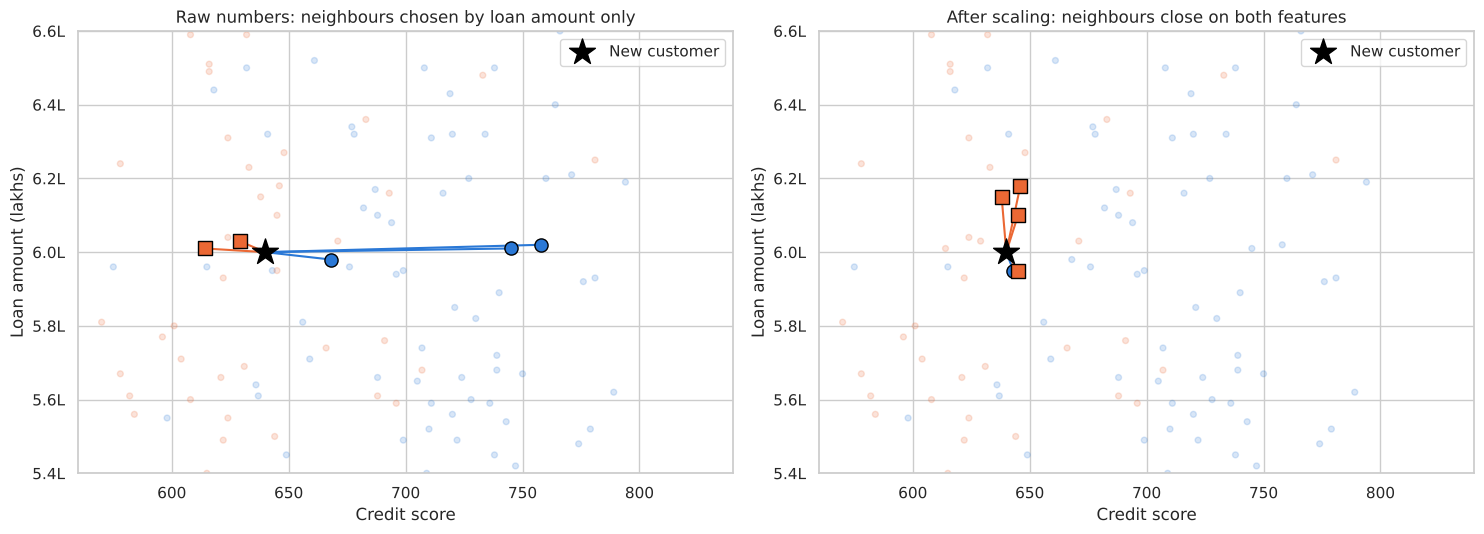

In [12]:
# Two charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# The two neighbour sets we calculated above, each with a title for its chart.
versions = [(nearest_raw, "Raw numbers: neighbours chosen by loan amount only"),
            (nearest_scaled, "After scaling: neighbours close on both features")]

# Draw the same chart twice, once for each neighbour set.
for ax, (neighbours, title) in zip(axes, versions):

    # All 1,000 customers as faint dots in the background.
    ax.scatter(df["credit_score"], df["loan_amount"],
               c=df["default"].map({0: BLUE, 1: ORANGE}), alpha=0.18, s=18)

    # Go through the 5 neighbours one at a time.
    for _, neighbour in neighbours.iterrows():

        # Pick the colour and marker shape from the neighbour's answer.
        colour = ORANGE if neighbour["default"] == 1 else BLUE
        marker = "s" if neighbour["default"] == 1 else "o"

        # A line from the new customer to this neighbour.
        ax.plot([new_score, neighbour["credit_score"]], [new_loan, neighbour["loan_amount"]],
                color=colour, linewidth=1.5, zorder=2)

        # The neighbour itself as a solid, larger marker.
        ax.scatter(neighbour["credit_score"], neighbour["loan_amount"],
                   color=colour, marker=marker, s=90, edgecolor="black", zorder=3)

    # The new customer as a black star.
    ax.scatter(new_score, new_loan, marker="*", s=380, color="black", zorder=4, label="New customer")

    # Zoom in around the new customer so the neighbours are visible.
    ax.set_xlim(560, 840)
    ax.set_ylim(540000, 660000)

    # Axis formatting, labels and title.
    ax.yaxis.set_major_formatter(lambda value, position: f"{value / 100000:.1f}L")
    ax.set_xlabel("Credit score")
    ax.set_ylabel("Loan amount (lakhs)")
    ax.set_title(title)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

**Reading the output:**

- **Left chart (raw numbers):** the 5 neighbours are spread left to right, from a credit score of 614 up to 758, but all at almost the same height. The lines are long and nearly horizontal. The model only matched on loan amount.
- **Right chart (after scaling):** the 5 neighbours are packed tightly around the star. They match on both credit score and loan amount.

**The rule to remember: always scale the features before KNN.** KNN is built entirely on distance, and distance is controlled by whichever column has the biggest numbers.

That was KNN. Everything from here on is the same procedure, done by the library, using all 6 features instead of 2.

---
# Step 6: Split the data into train and test

**The problem:** if we check the model on the same customers it has stored, it will look perfect, because each customer's nearest neighbour is itself. That tells us nothing about new customers.

**The fix:** hide some customers from the model.

- **Training set (80% = 800 customers):** the model stores these. They are the "past customers" used as neighbours.
- **Test set (20% = 200 customers):** the model never sees these while we build it. At the very end, we ask the model to predict them and compare with the true answers.

The test set plays the role of "new customers the bank has not seen yet".

In [13]:
# X = the 6 feature columns (the inputs). By convention it is written as a capital X.
X = df.drop(columns="default")

# y = the answer column (the target). By convention it is written as a small y.
y = df["default"]

# Split both X and y into a training part and a testing part.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% of the customers go to the test set
    random_state=42,    # fixed so the same customers are picked every time we run this
    stratify=y,         # keep the same share of defaulters in both parts
)

# Check the sizes of the two parts.
print("Training set:", X_train.shape[0], "customers")
print("Test set    :", X_test.shape[0], "customers")

# Check that the default rate is about the same in both parts.
print(f"\nDefault rate in training set: {y_train.mean() * 100:.1f}%")
print(f"Default rate in test set    : {y_test.mean() * 100:.1f}%")

Training set: 800 customers
Test set    : 200 customers

Default rate in training set: 29.5%
Default rate in test set    : 29.5%


**Reading the output:** 800 customers for training and 200 for testing. The default rate is 29.5% in both the training set and the test set.

**What `stratify=y` did:** without it, the 200 test customers are picked purely at random, and by bad luck we could get, say, 22% defaulters in the test set and 31% in training. Then the test would not represent the real mix. `stratify=y` forces both parts to keep the same ratio as the full data.

**The do-nothing score on the test set:** 29.5% defaulted, so predicting "repaid" for everyone gives **70.5%** accuracy. That is the number to beat.

---
# Step 7: Scale the features

We saw in Step 5 why scaling is needed. Now we do it properly for all 6 features using `StandardScaler`, which applies the same formula: (value - average) / spread.

**One rule that is easy to get wrong:**

1. Calculate the averages and spreads from the **training set only** (`fit`).
2. Use those same averages and spreads to convert **both** the training set and the test set (`transform`).

**Why not use the test set to calculate averages?** The test set stands for future customers. In real life, when you build the model, those customers do not exist yet, so you cannot know their average. If the test set influences anything during building, the final score is no longer an honest check.

In [14]:
# Create the scaler. At this point it knows nothing.
scaler = StandardScaler()

# fit(): calculate the average and spread of each column, from the training set only.
scaler.fit(X_train)

# transform(): apply (value - average) / spread to the training set.
X_train_scaled = scaler.transform(X_train)

# transform(): apply the SAME training averages and spreads to the test set.
X_test_scaled = scaler.transform(X_test)

# Build a small table to compare each column's range before and after scaling.
before_after = pd.DataFrame({
    "min before": X_train.min(),
    "max before": X_train.max(),
    "min after": X_train_scaled.min(axis=0),    # axis=0 means "down each column"
    "max after": X_train_scaled.max(axis=0),
})

# Show the comparison.
before_after

,min before,max before,min after,max after
age,21,60,-1.68,1.67
monthly_income,15000,129900,-2.06,3.22
credit_score,435,900,-2.88,2.79
loan_amount,30000,1637000,-1.55,3.93
missed_payments,0,5,-1.07,3.76
years_employed,0,39,-1.14,3.17


**Reading the output:** compare the "before" and "after" columns.

- **Before:** `loan_amount` runs up to 16,37,000 while `missed_payments` runs only up to 5. Completely different ranges.
- **After:** every column sits roughly between -3 and +4. They are now comparable.
- **Reading one value:** the largest loan (16,37,000) becomes 3.93, meaning it is almost 4 typical steps above the average loan. The youngest age (21) becomes -1.68, meaning 1.68 typical steps below the average age.

The data has not lost any information. The **order** of customers within each column is exactly the same. Only the unit has changed, from "rupees" or "years" to "steps away from the average".

## Does scaling really change the result? Test it.

We train the same KNN model twice: once on raw numbers, once on scaled numbers, and compare accuracy on the test set.

Do-nothing score (always say 'repaid'): 70.5%
KNN without scaling                   : 69.5%
KNN with scaling                      : 84.0%


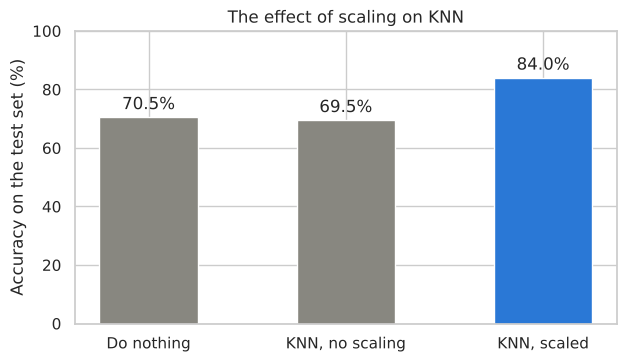

In [15]:
# Model A: KNN with K = 5, trained on the RAW (unscaled) training data.
# fit() for KNN simply stores the training customers. No calculation happens yet.
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)

# Model B: the same KNN with K = 5, trained on the SCALED training data.
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)

# predict() runs the full KNN procedure for each test customer:
# distance to all 800 training customers -> sort -> take 5 nearest -> majority vote.
predictions_raw = knn_raw.predict(X_test)
predictions_scaled = knn_scaled.predict(X_test_scaled)

# accuracy_score = (number of correct predictions) / (number of predictions).
accuracy_raw = accuracy_score(y_test, predictions_raw)
accuracy_scaled = accuracy_score(y_test, predictions_scaled)

# The do-nothing score: the share of test customers who repaid.
do_nothing = 1 - y_test.mean()

# Print the three numbers side by side.
print(f"Do-nothing score (always say 'repaid'): {do_nothing * 100:.1f}%")
print(f"KNN without scaling                   : {accuracy_raw * 100:.1f}%")
print(f"KNN with scaling                      : {accuracy_scaled * 100:.1f}%")

# The same three numbers as a bar chart.
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(["Do nothing", "KNN, no scaling", "KNN, scaled"],
              [do_nothing * 100, accuracy_raw * 100, accuracy_scaled * 100],
              color=["#888780", "#888780", BLUE], width=0.5)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("Accuracy on the test set (%)")
ax.set_title("The effect of scaling on KNN")
ax.set_ylim(0, 100)
plt.show()

**Reading the output:**

- **Do nothing: 70.5%.** The score for predicting "repaid" every time.
- **KNN without scaling: 69.5%.** Slightly **worse** than doing nothing. The model matched customers almost only on loan amount and income (the big-number columns), which are weak signals. All that calculation gave no benefit.
- **KNN with scaling: 84.0%.** 14.5 percentage points higher than without scaling. In a test set of 200 customers, that is 29 more correct predictions.

Same data, same algorithm, same K. The only change was scaling. For KNN, scaling is not an optional clean-up step. It decides whether the model works at all.

---
# Step 8: A cleaner way to write it — the pipeline

In Step 7 we had to remember two things in the right order: scale, then KNN. If someone forgets to scale a new customer before predicting, the answer is silently wrong.

A **pipeline** joins the two steps into one object. Whatever data you give it goes through this flow automatically:

`raw data → StandardScaler → KNeighborsClassifier → prediction`

From here on, we use the pipeline and pass it raw (unscaled) data. It does the scaling inside.

In [16]:
# Build a pipeline with two steps: first scale, then KNN with K = 5.
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# fit() on RAW training data. Inside, the pipeline:
#   1. calculates averages and spreads from X_train and scales it,
#   2. hands the scaled data to KNN, which stores it.
model.fit(X_train, y_train)

# score() on RAW test data. Inside, the pipeline:
#   1. scales X_test with the training averages and spreads,
#   2. runs KNN predictions,
#   3. returns the accuracy.
print(f"Pipeline accuracy on the test set: {model.score(X_test, y_test) * 100:.1f}%")

Pipeline accuracy on the test set: 84.0%


**Reading the output:** 84.0%, exactly the same as the manual "scale then KNN" in Step 7. The pipeline does the same work with less code and no chance of forgetting the scaling step.

---
# Step 9: Find the best K

So far we used K = 5 without any reason. K is a setting **we** choose, and it changes the predictions.

- **Small K (for example 1):** the prediction copies the single nearest customer. If that one customer is unusual, the prediction is wrong. The model reacts to every small accident in the data. This is called **overfitting**: the model fits the stored customers perfectly but does poorly on new ones.
- **Large K (for example 401):** hundreds of customers vote, including ones that are not similar at all. Since 70% of all customers repaid, "repaid" wins almost every vote. The model ignores the details of the new customer. This is called **underfitting**.
- **The right K is somewhere in between,** and we find it by testing.

## How do we test K without touching the test set?

We must not use the 200 test customers to pick K. If we did, we would be choosing the K that happens to suit those exact 200 customers, and the final score would look better than it really is.

Instead we use **5-fold cross-validation** on the 800 training customers:

1. Cut the 800 training customers into 5 equal parts of 160.
2. Round 1: store parts 2, 3, 4, 5 (640 customers). Predict part 1 (160 customers). Note the accuracy.
3. Round 2: store parts 1, 3, 4, 5. Predict part 2. Note the accuracy.
4. Continue until each of the 5 parts has been predicted exactly once.
5. Take the average of the 5 accuracies.

That average is a reliable estimate of how the model does on customers it has not stored, and the test set stays untouched.

We repeat this for K = 1, 3, 5, ... up to 29. We use only odd numbers so that a two-way vote can never tie.

**Why stop at 29?** A common rule of thumb is to search up to about the square root of the number of training rows. We have 800 training customers, and the square root of 800 is about 28.

In [17]:
# The K values to try: 1, 3, 5, ..., 29. range(start, stop, step) stops before 30.
k_values = list(range(1, 30, 2))

# Two empty lists to collect the results for each K.
train_scores = []   # accuracy on the same customers the model stored
cv_scores = []      # average accuracy from 5-fold cross-validation

# Try each K one by one.
for k in k_values:

    # A fresh pipeline (scale, then KNN) using this K.
    candidate = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

    # Training accuracy: store the 800 customers, then predict those same 800.
    candidate.fit(X_train, y_train)
    train_scores.append(candidate.score(X_train, y_train))

    # Cross-validation accuracy: the 5-round procedure described above. cv=5 means 5 parts.
    # It returns 5 accuracies, and mean() averages them.
    cv_scores.append(cross_val_score(candidate, X_train, y_train, cv=5).mean())

# Put the results into a table.
k_results = pd.DataFrame({"K": k_values,
                          "train_accuracy_%": np.array(train_scores) * 100,
                          "cv_accuracy_%": np.array(cv_scores) * 100})

# idxmax() finds the row with the highest cross-validation accuracy.
best_row = k_results.loc[k_results["cv_accuracy_%"].idxmax()]
best_k = int(best_row["K"])

# Show the full table and the best K.
print(k_results.round(1).to_string(index=False))
print(f"\nBest K by cross-validation: {best_k}  (accuracy {best_row['cv_accuracy_%']:.1f}%)")

 K  train_accuracy_%  cv_accuracy_%
 1            100.00          75.20
 3             87.20          77.20
 5             84.00          79.40
 7             84.10          79.50
 9             84.60          80.10
11             83.60          80.70
13             83.40          79.40
15             83.10          81.00
17             82.60          79.90
19             83.20          80.40
21             83.10          80.10
23             82.60          80.60
25             82.60          80.60
27             82.50          80.20
29             83.00          80.50

Best K by cross-validation: 15  (accuracy 81.0%)


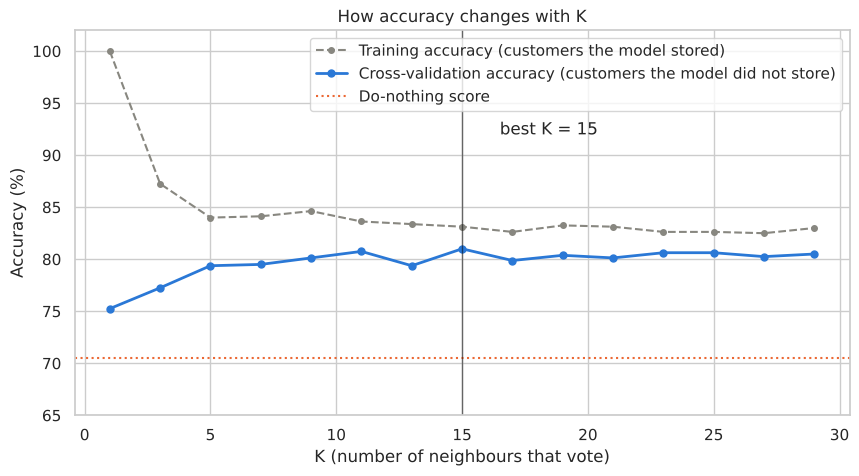

In [18]:
# Draw the two accuracy lines against K.
fig, ax = plt.subplots(figsize=(10, 5))

# Line 1: accuracy on the customers the model stored (dashed grey).
ax.plot(k_results["K"], k_results["train_accuracy_%"], color="#888780", linestyle="--",
        marker="o", markersize=4, label="Training accuracy (customers the model stored)")

# Line 2: cross-validation accuracy (solid blue). This is the one we trust.
ax.plot(k_results["K"], k_results["cv_accuracy_%"], color=BLUE, linewidth=2,
        marker="o", markersize=5, label="Cross-validation accuracy (customers the model did not store)")

# A horizontal line at the do-nothing score of the training set.
ax.axhline((1 - y_train.mean()) * 100, color=ORANGE, linestyle=":", label="Do-nothing score")

# A vertical line at the best K.
ax.axvline(best_k, color="black", linewidth=1, alpha=0.5)
ax.annotate(f"best K = {best_k}", xy=(best_k, 92), xytext=(best_k + 1.5, 92))

# Labels, title, legend.
ax.set_xlabel("K (number of neighbours that vote)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("How accuracy changes with K")
ax.set_ylim(65, 102)
ax.legend(loc="upper right")
plt.show()

**Reading the output, from left to right:**

**At K = 1:**
- Training accuracy (grey dashed) is **100%**. Of course it is: each stored customer's nearest neighbour is itself, so it always "predicts" its own answer.
- Cross-validation accuracy (blue) is only **75.2%**, not far above the do-nothing line.
- This large gap between 100% and 75.2% is what overfitting looks like. The model is perfect on what it stored and much weaker on anything new.

**From K = 1 to K = 5:** the blue line climbs from 75.2% to 79.4%. More voters means one unusual neighbour can no longer decide the answer alone.

**From K = 5 onwards:** the blue line is nearly flat, moving between about 79.4% and 81.0%. The two lines also come close together (about 2 to 3 points apart), which means the model behaves almost the same on stored and unstored customers. That is what we want.

**The best K:** the highest cross-validation accuracy is at **K = 15 (81.0%)**.

**An honest note on "best":** K = 11 gives 80.7%, K = 15 gives 81.0% and K = 23 gives 80.6%. A difference of 0.3 points is 2 or 3 customers out of 800. It is too small to mean anything. The correct reading of this chart is: **any K from about 9 to 29 works about equally well, and very small K (1 or 3) is clearly worse.** We go with 15 because it is the top value and it sits in the middle of the flat, stable region.

**Why 100% training accuracy should never impress you:** the grey line shows the model checking itself on answers it already has. Only the blue line, or a test set, tells you how the model handles customers it has not seen.

---
# Step 10: Final check on the hidden test customers

We now build the final model with the best K, store all 800 training customers, and predict the 200 test customers. This is the first and only time the test set is used to judge the final model.

In [19]:
# The final pipeline: scale, then KNN with the best K found in Step 9.
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))

# Store all 800 training customers.
final_model.fit(X_train, y_train)

# Predict the 200 test customers.
test_predictions = final_model.predict(X_test)

# Accuracy = correct predictions / all predictions.
final_accuracy = accuracy_score(y_test, test_predictions)

# Print it next to the do-nothing score.
print(f"K used                 : {best_k}")
print(f"Do-nothing score       : {(1 - y_test.mean()) * 100:.1f}%")
print(f"Final model accuracy   : {final_accuracy * 100:.1f}%")
print(f"Correct predictions    : {(test_predictions == y_test).sum()} out of {len(y_test)}")

K used                 : 15
Do-nothing score       : 70.5%
Final model accuracy   : 83.0%
Correct predictions    : 166 out of 200


**Reading the output:** the final model is correct for **166 of the 200** hidden customers, which is **83.0%**. The do-nothing score is 70.5%, so the model is clearly useful.

**Wait, K = 5 scored 84.0% on this test set in Step 8. Should we go back to K = 5?** No, for two reasons:

1. The gap is 1 point, which is 2 customers out of 200. With a test set this small, 2 customers either way is chance.
2. If we pick K by looking at the test score, the test set is no longer a hidden check. We would be tuning the model to these exact 200 customers. Cross-validation said K = 15 using 800 customers and 5 rounds, which is the more reliable evidence. We keep K = 15 and report 83.0% as it is.

But accuracy is one number that hides important detail. It treats all mistakes as equal. For a bank they are not equal:

- Predicting "will repay" for someone who then **defaults** → the bank loses the loan money.
- Predicting "will default" for someone who would have **repaid** → the bank loses one good customer.

To see which mistakes the model makes, we use a confusion matrix.

## The confusion matrix

**How to read it:** it is a 2 × 2 table. Rows are what **actually** happened. Columns are what the model **predicted**. Each cell is a count of customers.

| | Predicted: repaid | Predicted: defaulted |
|---|---|---|
| **Actually repaid** | Correct | Mistake: good customer flagged |
| **Actually defaulted** | Mistake: defaulter missed | Correct |

The two cells on the diagonal (top-left, bottom-right) are correct predictions. The other two are mistakes.

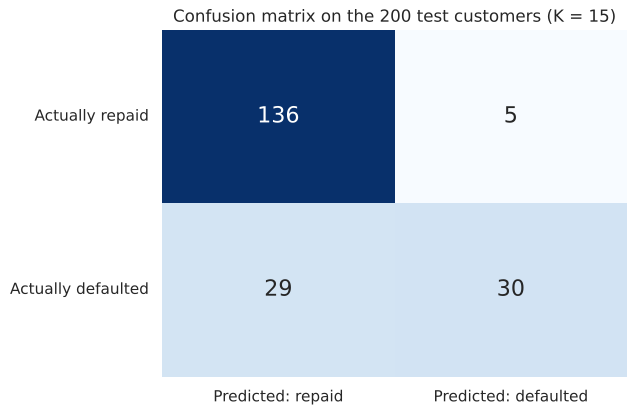

Repaid, and predicted repaid       : 136
Repaid, but predicted defaulted    : 5
Defaulted, but predicted repaid    : 29
Defaulted, and predicted defaulted : 30


In [20]:
# Build the 2x2 table: rows = actual answers, columns = predicted answers.
matrix = confusion_matrix(y_test, test_predictions)

# Create the chart area.
fig, ax = plt.subplots(figsize=(6, 4.5))

# Draw the table as coloured cells with the counts written inside.
sns.heatmap(
    matrix,
    annot=True,                 # write the count in each cell
    fmt="d",                    # "d" = whole numbers
    cmap="Blues",               # darker blue = larger count
    cbar=False,                 # no colour scale bar needed
    annot_kws={"size": 16},     # larger numbers
    xticklabels=["Predicted: repaid", "Predicted: defaulted"],
    yticklabels=["Actually repaid", "Actually defaulted"],
    ax=ax,
)

# Keep the row labels horizontal so they are easy to read.
ax.tick_params(axis="y", rotation=0)

# Title and show.
ax.set_title(f"Confusion matrix on the 200 test customers (K = {best_k})")
plt.show()

# ravel() unpacks the 4 cells into 4 named numbers, reading left to right, top to bottom.
correct_repaid, wrongly_flagged, missed_defaulters, correct_default = matrix.ravel()

# Print each cell in plain words.
print(f"Repaid, and predicted repaid       : {correct_repaid}")
print(f"Repaid, but predicted defaulted    : {wrongly_flagged}")
print(f"Defaulted, but predicted repaid    : {missed_defaulters}")
print(f"Defaulted, and predicted defaulted : {correct_default}")

**Reading the output:**

- **Top-left, 136:** customers who repaid, and the model said "repaid". Correct.
- **Top-right, 5:** customers who repaid, but the model said "defaulted". The bank would have wrongly turned away 5 good customers.
- **Bottom-left, 29:** customers who defaulted, but the model said "repaid". **These are the costly mistakes.** The bank would have given loans to 29 people who did not pay back.
- **Bottom-right, 30:** customers who defaulted, and the model said "defaulted". Correct.

Check: 136 + 30 = 166 correct, which matches the 83.0% accuracy.

**The important finding:** there were 59 actual defaulters in the test set (29 + 30). The model caught 30 and **missed 29**. So although overall accuracy is 83%, the model catches only about half of the defaulters.

## Precision and recall: two numbers that describe this

Both are calculated for the "defaulted" class.

- **Recall** answers: *of all customers who actually defaulted, what share did the model catch?*
  30 caught out of 59 actual defaulters = **51%**.
- **Precision** answers: *of all customers the model flagged as defaulters, what share really defaulted?*
  30 real defaulters out of 35 flagged (30 + 5) = **86%**.

In [21]:
# classification_report calculates precision and recall for each class in one go.
print(classification_report(y_test, test_predictions, target_names=["Repaid (0)", "Defaulted (1)"]))

               precision    recall  f1-score   support

   Repaid (0)       0.82      0.96      0.89       141
Defaulted (1)       0.86      0.51      0.64        59

     accuracy                           0.83       200
    macro avg       0.84      0.74      0.76       200
 weighted avg       0.83      0.83      0.81       200



**Reading the output:**

- **Row `Defaulted (1)`:** precision 0.86, recall 0.51. These match what we calculated by hand above.
- **Row `Repaid (0)`:** precision 0.82, recall 0.96. The model is very good at recognising repayers: it correctly identifies 96% of them (136 of 141).
- **`f1-score`:** a single number that combines precision and recall. It is high only when both are high. 0.64 for defaulters vs 0.89 for repayers confirms the model is weaker on defaulters.
- **`support`:** how many test customers are in each class (141 repaid, 59 defaulted).
- **`accuracy`:** 0.83, the same number as before.
- **`macro avg` and `weighted avg`:** averages of the two rows above. `macro` treats both classes equally. `weighted` gives the larger class (repaid) more weight.

**In plain words:** when this model says "this customer will default", it is right 86% of the time. But it stays silent on 49% of the real defaulters.

**Why KNN misses defaulters here:** repayers are 70% of the data. In the mixed middle area of the scatter plot, any group of 15 neighbours will usually contain more repayers than defaulters, simply because there are more of them. So close votes tend to go to "repaid". This is the effect of imbalanced classes on a majority vote.

**What a bank would do about it:** instead of flagging a customer only when more than half the neighbours defaulted, flag them when, say, 30% or more defaulted. That catches more defaulters (higher recall) at the cost of wrongly flagging more good customers (lower precision). Which trade-off is right depends on how much a missed defaulter costs compared to a lost good customer. That is a business decision, not a KNN setting. Practice task 4 at the end lets you try it.

---
# Step 11: See what K does to the prediction areas

This chart makes the effect of K visible. We go back to two features (`credit_score` and `loan_amount`) so that it can be drawn.

**How the chart is made:** we cover the whole chart area with a fine grid of imaginary customers, one for every combination of credit score and loan amount. We ask the model to predict each of them, and colour the background by the answer.

- **Blue background** = a customer at this spot would be predicted "repaid".
- **Orange background** = a customer at this spot would be predicted "defaulted".
- The line where the colours meet is where the model's answer flips.

The dots on top are the real training customers.

K =   1: flags 235 training customers as defaulters (real defaulters in the training set: 236)


K =  15: flags 194 training customers as defaulters (real defaulters in the training set: 236)


K = 401: flags 9 training customers as defaulters (real defaulters in the training set: 236)


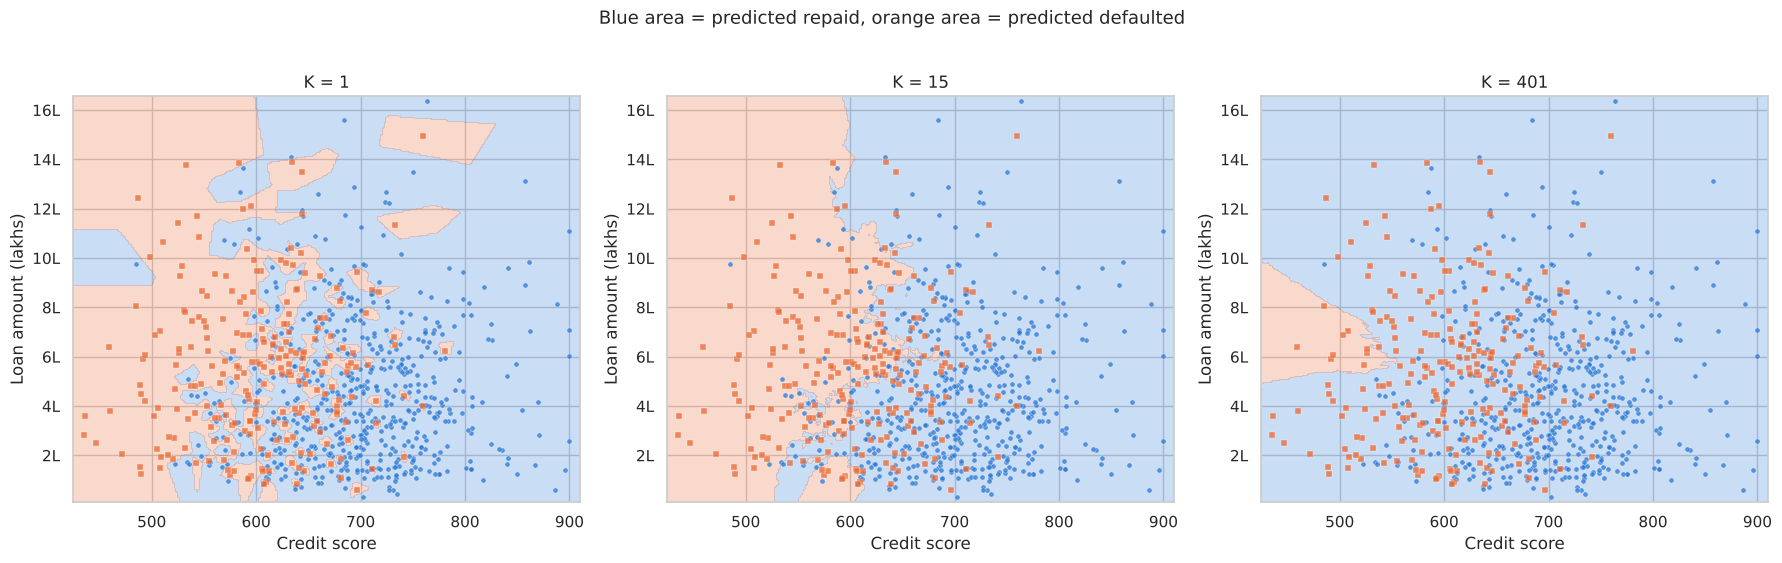

In [22]:
# The two features used for this picture.
two_features = ["credit_score", "loan_amount"]

# Build the grid of imaginary customers.
# linspace(start, stop, 300) gives 300 evenly spaced values between start and stop.
score_values = np.linspace(X_train["credit_score"].min() - 10, X_train["credit_score"].max() + 10, 300)
loan_values = np.linspace(X_train["loan_amount"].min() - 20000, X_train["loan_amount"].max() + 20000, 300)

# meshgrid() creates every combination: 300 x 300 = 90,000 imaginary customers.
score_grid, loan_grid = np.meshgrid(score_values, loan_values)

# Put the 90,000 customers into a table with the same two column names the model was trained on.
# ravel() flattens each 300x300 grid into one long list of 90,000 values.
grid_customers = pd.DataFrame({"credit_score": score_grid.ravel(), "loan_amount": loan_grid.ravel()})

# Three charts side by side: a very small K, the best K, and a very large K.
k_to_show = [1, best_k, 401]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, k in zip(axes, k_to_show):

    # A pipeline (scale, then KNN) trained on the two features only.
    boundary_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    boundary_model.fit(X_train[two_features], y_train)

    # Predict all 90,000 grid customers, then reshape the answers back into a 300x300 grid.
    grid_predictions = boundary_model.predict(grid_customers).reshape(score_grid.shape)

    # Colour the background by the prediction: blue where 0, orange where 1.
    ax.contourf(score_grid, loan_grid, grid_predictions, levels=[-0.5, 0.5, 1.5],
                colors=[BLUE, ORANGE], alpha=0.25)

    # Draw the real training customers on top: circles for repaid, squares for defaulted.
    for answer, colour, marker in [(0, BLUE, "o"), (1, ORANGE, "s")]:
        group = X_train[y_train == answer]
        ax.scatter(group["credit_score"], group["loan_amount"], color=colour, marker=marker,
                   s=14, alpha=0.75, edgecolor="white", linewidth=0.3)

    # Axis formatting, labels and title.
    ax.yaxis.set_major_formatter(lambda value, position: f"{value / 100000:.0f}L")
    ax.set_xlabel("Credit score")
    ax.set_ylabel("Loan amount (lakhs)")
    ax.set_title(f"K = {k}")

    # Count how many of the 800 training customers this model would flag as defaulters.
    flagged = int(boundary_model.predict(X_train[two_features]).sum())
    print(f"K = {k:>3}: flags {flagged} training customers as defaulters "
          f"(real defaulters in the training set: {int(y_train.sum())})")

fig.suptitle("Blue area = predicted repaid, orange area = predicted defaulted", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Reading the output:**

- **K = 1 (left):** the background is broken into many small patches. There are orange patches deep inside the blue area (look at the top right, around a credit score of 760 and a loan of 15 lakh) and blue patches inside the orange area. Each patch exists because of **one** customer. A single defaulter with a high credit score creates an orange patch around itself, and any new customer who lands there is predicted "defaulted" because of that one person. This is overfitting, seen as a picture. The printed line confirms it: the model flags 235 of the training customers, almost exactly the 236 real defaulters, because it is simply repeating each stored customer's own answer.

- **K = 15 (middle):** two large areas. Orange on the left (low credit score), blue on the right. The isolated patches are gone, and only a few small bumps remain along the dividing line. The line sits at a credit score of roughly 600 to 650 and it is not straight: for loans under 4 lakh the colour changes at about 600, while for loans between about 5 and 10 lakh the orange area reaches further right, to about 650. So in that range, **a bigger loan needs a better credit score to be predicted as repaid**. (Above 12 lakh there are very few customers, so the line there rests on a handful of points.) It flags 194 training customers.

- **K = 401 (right):** the orange area has shrunk to one wedge on the far left (credit score below about 550, loans between 5 and 10 lakh), and the model flags only 9 customers out of 236 real defaulters. With 401 voters, most of them are not similar to the new customer at all, and since repayers are the majority overall, "repaid" wins almost everywhere. The model has nearly stopped looking at the customer's details. This is underfitting.

**The extreme case:** there are only 236 defaulters among the 800 training customers. So if K is 473 or more, defaulters can never be the majority of the voters, and the model predicts "repaid" for every customer, whatever their details. At that point KNN has become the do-nothing model from Step 3.

**Summary of K:**

| K | What decides the prediction | Result |
|---|---|---|
| Too small | One or two nearby customers, including unusual ones | Overfitting: patchy, unreliable |
| Balanced | A local group of similar customers | Captures the real pattern |
| Too large | The overall majority in the whole dataset | Underfitting: ignores the customer |

---
# Step 12: Predict for brand new customers

This is how the model would be used in practice. Three new loan applications arrive. We pass their raw details to the final model (all 6 features). The pipeline scales them and runs KNN.

We ask for two things:

- `predict()` → the answer: 0 (repaid) or 1 (defaulted).
- `predict_proba()` → the share of the K neighbours that voted for each answer. With K = 15, if 12 neighbours defaulted, the default share is 12 / 15 = 80%.

In [23]:
# Three new customers, written with the same 6 columns in the same order as the training data.
new_customers = pd.DataFrame({
    "age":             [45,     27,     35],
    "monthly_income":  [90000,  40000,  60000],
    "credit_score":    [790,    560,    655],
    "loan_amount":     [400000, 520000, 480000],
    "missed_payments": [0,      3,      1],
    "years_employed":  [18,     2,      9],
}, index=["Customer A", "Customer B", "Customer C"])

# predict(): the final answer for each customer.
answers = final_model.predict(new_customers)

# predict_proba(): two numbers per customer -> [share voting repaid, share voting defaulted].
# [:, 1] picks the second number (the default share) for every customer.
default_share = final_model.predict_proba(new_customers)[:, 1]

# Add the results to a copy of the table so the inputs and outputs are shown together.
results = new_customers.copy()
results["neighbours_defaulted"] = (default_share * best_k).round().astype(int)
results["default_share_%"] = default_share * 100
results["prediction"] = np.where(answers == 1, "DEFAULT", "REPAY")

# Show the table.
results

,age,monthly_income,credit_score,loan_amount,missed_payments,years_employed,neighbours_defaulted,default_share_%,prediction
Customer A,45,90000,790,400000,0,18,1,6.67,REPAY
Customer B,27,40000,560,520000,3,2,15,100.00,DEFAULT
Customer C,35,60000,655,480000,1,9,5,33.33,REPAY


**Reading the output:**

- **Customer A** (score 790, no missed payments, 18 years employed): **1 of the 15** most similar past customers defaulted (6.67%). Prediction: REPAY. A clear case.
- **Customer B** (score 560, 3 missed payments, 2 years employed, loan is 13 times income): **15 of 15** similar past customers defaulted (100%). Prediction: DEFAULT. Also a clear case.
- **Customer C** (score 655, 1 missed payment): **5 of 15** similar past customers defaulted (33.33%). Prediction: REPAY, since the majority (10 of 15) repaid. But one in three similar customers defaulted, so this is far less certain than Customer A.

**How to use the share:** the prediction is the yes/no answer, and the share tells you how strong the vote was. Customer A and Customer C both come out as REPAY, but a bank would treat a 7% share and a 33% share very differently. Customer C is the kind of case to send for manual review.

## Open the box: who are Customer C's neighbours?

One strength of KNN is that every prediction can be explained by showing the actual past customers behind it. We ask the model for Customer C's 15 nearest neighbours and look at the first 8.

In [24]:
# The pipeline has two named steps. We take each one out to use it directly.
fitted_scaler = final_model.named_steps["standardscaler"]
fitted_knn = final_model.named_steps["kneighborsclassifier"]

# Pick Customer C. The double brackets keep it as a one-row table.
customer_c = new_customers.loc[["Customer C"]]

# Scale Customer C with the training averages and spreads (the pipeline normally does this for us).
customer_c_scaled = fitted_scaler.transform(customer_c)

# kneighbors() returns two things for the K nearest stored customers:
#   distances = how far each one is, positions = their row positions in the training set.
distances, positions = fitted_knn.kneighbors(customer_c_scaled)

# Look up those rows in the training table. iloc selects rows by position.
neighbours = X_train.iloc[positions[0]].copy()

# Attach each neighbour's real answer and its distance from Customer C.
neighbours["default"] = y_train.iloc[positions[0]].values
neighbours["distance"] = distances[0]

# Show Customer C first, then the 8 nearest neighbours.
print("Customer C:")
print(customer_c.to_string())
print(f"\nThe 8 nearest of the {best_k} neighbours:")
print(neighbours.head(8).to_string())

# Count the votes across all K neighbours.
print(f"\nAll {best_k} neighbours -> defaulted: {int(neighbours['default'].sum())}, "
      f"repaid: {int((neighbours['default'] == 0).sum())}")

Customer C:
            age  monthly_income  credit_score  loan_amount  missed_payments  years_employed
Customer C   35           60000           655       480000                1               9

The 8 nearest of the 15 neighbours:
     age  monthly_income  credit_score  loan_amount  missed_payments  years_employed  default  distance
314   30           57300           654       373000                1               7        1      0.62
728   40           66500           645       514000                1               6        0      0.64
755   38           60600           677       378000                1              13        1      0.67
584   37           58700           666       310000                1               6        0      0.71
634   28           61700           659       571000                1               7        0      0.72
10    42           68100           678       443000                1               9        0      0.77
636   30           52100           689 

**Reading the output:** compare each neighbour's row with Customer C's row (age 35, income 60,000, score 655, loan 4,80,000, 1 missed payment, 9 years employed).

The 8 neighbours shown are aged 28 to 42, earn about 45,000 to 68,000, have credit scores from 645 to 689, loans of about 3 to 5.7 lakh, 5 to 13 years of employment, and every one of them has exactly 1 missed payment. They are similar to Customer C on **all six** features at once, which is exactly what KNN is meant to find.

The `distance` column grows as you go down (0.62 to 0.86): the first neighbour is the most similar, and each next one is slightly less similar.

Look at the `default` column: 3 of these 8 defaulted, even though their details look much like the 5 who repaid. This is the randomness we built into the data in Step 2, and real customers behave the same way.

Across all 15 neighbours, 5 defaulted and 10 repaid, which gives the 33.33% share and the REPAY prediction from the previous table.

**This is why KNN is easy to explain to a non-technical person:** you can say "we predicted REPAY because out of the 15 most similar past customers, 10 repaid, and here they are."

---
# Step 13: Summary

## What we did, in order

1. Created 1,000 loan customers with 6 features and a known answer.
2. Found the do-nothing score (70.5%) so we had a number to beat.
3. Used charts to see that `credit_score` and `missed_payments` separate defaulters from repayers, while `age` and `monthly_income` on their own do not.
4. Did KNN by hand: distance to everyone → sort → take K nearest → majority vote.
5. Saw that without scaling, the largest-number column controls the distance.
6. Split into 800 training and 200 test customers.
7. Picked K with 5-fold cross-validation on the training customers only.
8. Scored 83.0% on the hidden test customers, and found the model misses about half of the defaulters.

## The core ideas of KNN

| Idea | What it means |
|---|---|
| No formula is learned | `fit()` only stores the training customers. All the work happens in `predict()`. |
| Similar = small distance | Distance is calculated from the differences in every feature. |
| K = number of voters | Small K overfits, large K underfits, choose K by cross-validation. |
| Scaling is required | Otherwise large-number columns control the distance. Here it was 69.5% without and 84.0% with (at K = 5). |
| Every prediction can be shown | You can list the exact past customers behind any answer. |

## When to use KNN, and when not to

**Use it when:**
- The dataset is small to medium (up to some tens of thousands of rows).
- There are a few meaningful numeric features.
- You need predictions that can be explained by pointing at similar past cases.
- You want a quick first model to compare others against.

**Avoid it when:**
- The dataset is very large. Every single prediction calculates the distance to every stored row.
- There are many features (hundreds). With that many, all rows end up at nearly the same distance from each other and "nearest" stops being meaningful.
- Many features are irrelevant. They add noise to the distance. (Practice task 2 tests this.)
- One class is rare. The majority class tends to win close votes, as we saw with the missed defaulters.

## Practice tasks

1. **Change the vote.** In Step 5, change `K = 5` to `K = 15` and rerun 5a, 5b and 5c. Does the prediction for the new customer change? How many of the 15 neighbours defaulted?
2. **Remove a weak column.** `age` and `monthly_income` looked weak in the histograms. Create `X_small = X.drop(columns=["age"])`, repeat Steps 6 and 9, and compare the cross-validation accuracy table with the original one. Then try dropping `monthly_income` instead. Do the two tables move in the same direction? Look at the risk formula in Step 2 and explain why `monthly_income` can still be useful to KNN even though its histogram showed no separation.
3. **Closer neighbours count more.** Replace `KNeighborsClassifier(n_neighbors=k)` with `KNeighborsClassifier(n_neighbors=k, weights="distance")` in Step 9. Now a nearer neighbour's vote counts more than a farther one's. What happens to the grey training line, and why?
4. **Catch more defaulters.** In Step 10, replace `final_model.predict(X_test)` with `(final_model.predict_proba(X_test)[:, 1] >= 0.3).astype(int)`. This flags a customer when 30% or more of the neighbours defaulted. Redraw the confusion matrix. How many defaulters are missed now, and how many good customers are wrongly flagged?
5. **Your own customer.** In Step 12, add a fourth customer with details of your choice and predict. Then list their nearest neighbours as we did for Customer C.